# 02 – Preparação dos dados

Item 4 do roteiro. Este notebook transforma a base bruta na base de modelagem.

**Divisão de responsabilidades para evitar vazamento**

| Onde | O quê | Por quê |
|---|---|---|
| Aqui (notebook 02) | Regras fixas: valores implausíveis viram ausentes, conversão de escala, logaritmos, resumos dos grupos de colunas, região | Não aprendem nada com os dados: a mesma regra vale para qualquer município, de qualquer ano |
| Dentro do `Pipeline` (notebook 03) | Limites de winsorização (p1/p99), mediana para imputação, média e desvio da padronização | Aprendem com os dados, então são ajustados só no treino de cada dobra e aplicados depois em 2025 |

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ / 'notebooks'))
import estilo_graficos as eg
from estilo_graficos import br

FIGURAS = RAIZ / 'figuras'
PROCESSADOS = RAIZ / 'dados' / 'processados'
eg.aplicar_estilo()
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', lambda x: br(x, 2))

bruta = pd.read_csv(RAIZ / 'dados' / 'brutos' / 'base_ideb_municipios.csv')
base = bruta.copy()
print(f'Base bruta: {br(len(base))} linhas e {base.shape[1]} colunas')

Base bruta: 10.561 linhas e 54 colunas


## 1. Gasto por aluno: valores implausíveis

Regra definida no notebook 01: gasto com ensino fundamental por aluno **abaixo de R$ 1 mil ou acima de R$ 60 mil por ano** é erro de declaração no Siconfi e vira ausente. Os limites são fixos e muito distantes dos percentis 1% (R$ 7 mil) e 99% (R$ 38,6 mil), então não dependem da amostra. Os extremos restantes serão limitados em p1/p99 do treino, dentro do pipeline.

In [2]:
GASTO_MIN, GASTO_MAX = 1_000, 60_000
gasto = base['gasto_ef_por_aluno']
implausivel = (gasto < GASTO_MIN) | (gasto > GASTO_MAX)

resumo_gasto = pd.DataFrame({
    'ausente na origem': gasto.isna().groupby(base['ano']).sum(),
    'implausível -> ausente': implausivel.groupby(base['ano']).sum(),
})
resumo_gasto['total ausente após a regra'] = resumo_gasto.sum(axis=1)
base.loc[implausivel, 'gasto_ef_por_aluno'] = np.nan
resumo_gasto

,ausente na origem,implausível -> ausente,total ausente após a regra
ano,,,
2023,34,9,43
2025,218,6,224


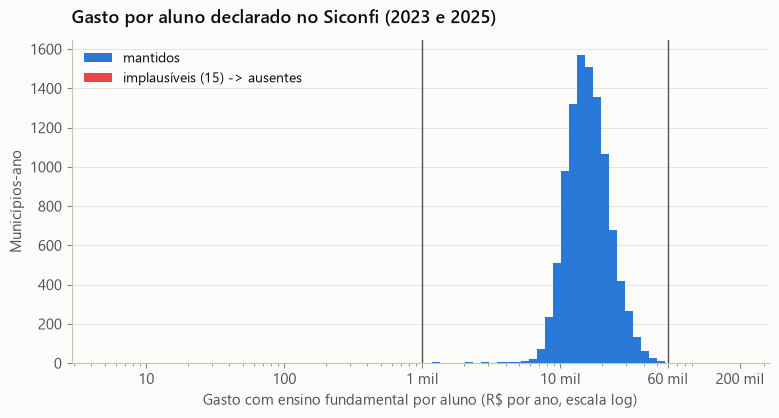

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.2))
valores = bruta['gasto_ef_por_aluno'].dropna()
bins = np.logspace(np.log10(valores.min()), np.log10(valores.max()), 80)
ax.hist(valores[valores.between(GASTO_MIN, GASTO_MAX)], bins=bins, color=eg.AZUL, label='mantidos')
ax.hist(valores[~valores.between(GASTO_MIN, GASTO_MAX)], bins=bins, color=eg.NEGATIVO,
        label=f'implausíveis ({(~valores.between(GASTO_MIN, GASTO_MAX)).sum()}) -> ausentes')
for limite in (GASTO_MIN, GASTO_MAX):
    ax.axvline(limite, color=eg.TINTA_SEC, linewidth=1)
ax.set_xscale('log')
ax.set_xticks([10, 100, 1_000, 10_000, 60_000, 200_000], ['10', '100', '1 mil', '10 mil', '60 mil', '200 mil'])
ax.set_xlabel('Gasto com ensino fundamental por aluno (R$ por ano, escala log)')
ax.set_ylabel('Municípios-ano')
ax.set_title('Gasto por aluno declarado no Siconfi (2023 e 2025)')
ax.legend(loc='upper left')
ax.grid(axis='x', visible=False)
eg.salvar_figura(fig, '02_gasto_por_aluno_tratamento', FIGURAS)
plt.show()

## 2. Conversão de escala

As colunas `pct_esc_*` (infraestrutura) e `pct_matr_*` (matrículas) vêm em fração de 0 a 1. Os indicadores do INEP (`dsu`, `afd`, `ird` etc.) vêm de 0 a 100. Passamos todas para 0 a 100, para que os coeficientes sejam lidos da mesma forma.

In [4]:
fracoes = [c for c in base.columns if c.startswith(('pct_esc_', 'pct_matr_'))]
assert base[fracoes].max().max() <= 1.0 + 1e-9
base[fracoes] = base[fracoes] * 100
base[fracoes].describe().loc[['min', '50%', 'max']]

,pct_matr_integral_ai,pct_matr_residencia_rural,pct_matr_transporte_publico,pct_esc_biblioteca,pct_esc_lab_informatica,pct_esc_lab_ciencias,pct_esc_quadra,pct_esc_internet_alunos,pct_esc_banda_larga,pct_esc_esgoto_rede,pct_esc_agua_potavel,pct_esc_energia_rede
min,"0,00","0,00","0,00","0,00","0,00","0,00","0,00","0,00","0,00","0,00","0,00","0,00"
50%,"10,57","34,75","34,12","60,00","16,67","0,00","50,00","45,71","100,00","28,57","100,00","100,00"
max,"100,00","99,17","100,00","100,00","100,00","100,00","100,00","100,00","100,00","100,00","100,00","100,00"


## 3. Resumo dos grupos de colunas que somam 100%

| Grupo do INEP | O que mede | Resumo adotado |
|---|---|---|
| AFD – adequação da formação docente | % de docentes em 5 grupos, do 1 (licenciatura na área em que leciona) ao 5 (sem superior) | `pct_formacao_adequada` = grupo 1 |
| IED – esforço docente | % de docentes em 6 níveis, do 1 (poucos alunos, um turno, uma escola) ao 6 (muitos alunos, três turnos, várias escolas) | `ied_medio` = média ponderada pelo nível (1 a 6) |
| ICG – complexidade de gestão | % de escolas em 6 níveis, do 1 (escola pequena, um turno, uma etapa) ao 6 (escola grande, três turnos, muitas etapas) | `icg_medio` = média ponderada pelo nível (1 a 6) |
| IRD – regularidade docente | % de docentes em 4 faixas de permanência na escola nos últimos anos | `ird_medio` = média ponderada (baixa = 1, média-baixa = 2, média-alta = 3, alta = 4) |

A % de docentes **sem** superior (AFD grupo 5) sai: tem correlação de −0,98 com a % **com** superior (`dsu`).

In [5]:
base['pct_formacao_adequada'] = base['afd_ef_anos_iniciais_grupo_1']
base['ied_medio'] = sum(n * base[f'ied_ef_anos_iniciais_nivel_{n}'] for n in range(1, 7)) / 100
base['icg_medio'] = sum(n * base[f'icg_nivel_{n}'] for n in range(1, 7)) / 100
base['ird_medio'] = (1 * base['ird_baixa_regularidade'] + 2 * base['ird_media_baixa']
                     + 3 * base['ird_media_alta'] + 4 * base['ird_alta']) / 100
base[['pct_formacao_adequada', 'ied_medio', 'icg_medio', 'ird_medio']].describe().loc[['min', '50%', 'max', 'count']]

,pct_formacao_adequada,ied_medio,icg_medio,ird_medio
min,"0,00","1,00","1,00","1,00"
50%,"78,90","2,30","2,14","2,67"
max,"100,00","4,30","6,00","4,00"
count,"10.545,00","10.554,00","10.560,00","10.558,00"


## 4. Features derivadas

- **Logaritmo** em população, PIB per capita, gasto por aluno e alunos por escola: são variáveis muito assimétricas, e no log uma mesma variação percentual tem o mesmo peso em municípios pequenos e grandes.
- **Alunos por escola** (matrículas dos anos iniciais ÷ número de escolas) substitui o número de escolas, que repete a população (correlação de 0,80). Mede se a rede é concentrada ou dispersa em muitas escolas pequenas.
- **Água e energia** são quase universais (mediana de 100% das escolas). Viram um único indicador, `infra_basica`, que marca as redes mais precárias. Esgoto da rede pública varia bastante e fica separado.
- **Região** a partir da UF.

In [6]:
REGIOES = {
    'Norte': ['RO', 'AC', 'AM', 'RR', 'PA', 'AP', 'TO'],
    'Nordeste': ['MA', 'PI', 'CE', 'RN', 'PB', 'PE', 'AL', 'SE', 'BA'],
    'Sudeste': ['MG', 'ES', 'RJ', 'SP'],
    'Sul': ['PR', 'SC', 'RS'],
    'Centro-Oeste': ['MS', 'MT', 'GO', 'DF'],
}
UF_REGIAO = {uf: regiao for regiao, ufs in REGIOES.items() for uf in ufs}

base['regiao'] = base['sigla_uf'].map(UF_REGIAO)
base['alunos_por_escola_ai'] = base['matriculas_ai'] / base['n_escolas_ai']
base['log_populacao'] = np.log(base['populacao'])
base['log_pib_per_capita'] = np.log(base['pib_per_capita_2023'])
base['log_gasto_ef_por_aluno'] = np.log(base['gasto_ef_por_aluno'])
base['log_alunos_por_escola_ai'] = np.log(base['alunos_por_escola_ai'])
base['infra_basica'] = base[['pct_esc_agua_potavel', 'pct_esc_energia_rede']].mean(axis=1)

assert base['regiao'].notna().all()
print('Linhas com log infinito:', np.isinf(base.filter(like='log_')).sum().sum())

Linhas com log infinito: 0


## 5. Conjunto final de features

In [7]:
FEATURES = {
    'Contexto socioeconômico': ['inse_medio_2015', 'log_pib_per_capita', 'log_populacao',
                                'pct_matr_residencia_rural'],
    'Escala e oferta': ['log_alunos_por_escola_ai', 'alunos_por_docente_ai',
                        'pct_matr_transporte_publico', 'pct_matr_integral_ai'],
    'Professores e gestão': ['atu_ef_anos_iniciais', 'had_ef_anos_iniciais', 'dsu_ef_anos_iniciais',
                             'pct_formacao_adequada', 'ied_medio', 'icg_medio', 'ird_medio'],
    'Infraestrutura': ['pct_esc_biblioteca', 'pct_esc_quadra', 'pct_esc_lab_informatica',
                       'pct_esc_lab_ciencias', 'pct_esc_internet_alunos', 'pct_esc_banda_larga',
                       'pct_esc_esgoto_rede', 'infra_basica'],
    'Gasto': ['log_gasto_ef_por_aluno'],
}
NUMERICAS = [c for cols in FEATURES.values() for c in cols]
CATEGORICAS = ['regiao']
CHAVES = ['ano', 'id_municipio', 'sigla_uf']
ALVO = 'ideb'

# Checagem de vazamento: nada que entre no cálculo do IDEB nem a meta projetada
PROIBIDAS = ('aprovacao', 'rendimento', 'saeb', 'reprovacao', 'abandono', 'distorcao', 'tdi',
             'promocao', 'repetencia', 'evasao', 'meta_ideb', 'ideb')
assert not [c for c in NUMERICAS + CATEGORICAS if any(p in c for p in PROIBIDAS)]

pd.DataFrame([(grupo, c, eg.rotulo(c)) for grupo, cols in FEATURES.items() for c in cols],
             columns=['grupo', 'feature', 'descrição'])

,grupo,feature,descrição
0,Contexto socioeconômico,inse_medio_2015,INSE 2015
1,Contexto socioeconômico,log_pib_per_capita,PIB per capita (log)
2,Contexto socioeconômico,log_populacao,População (log)
3,Contexto socioeconômico,pct_matr_residencia_rural,% matrículas de residentes rurais
4,Escala e oferta,log_alunos_por_escola_ai,Alunos por escola (log)
5,Escala e oferta,alunos_por_docente_ai,Alunos por docente
6,Escala e oferta,pct_matr_transporte_publico,% matrículas com transporte público
7,Escala e oferta,pct_matr_integral_ai,% matrículas em tempo integral
8,Professores e gestão,atu_ef_anos_iniciais,Alunos por turma
9,Professores e gestão,had_ef_anos_iniciais,Horas-aula por dia


In [8]:
print(f'{len(NUMERICAS)} features numéricas + região (one-hot, 4 colunas)')

ausentes = pd.DataFrame({
    f'municípios sem o valor ({ano})': base.loc[base['ano'] == ano, NUMERICAS].isna().sum()
    for ano in (2023, 2025)
})
ausentes['% em 2023'] = ausentes.iloc[:, 0] / (base['ano'] == 2023).sum() * 100
ausentes['% em 2025'] = ausentes.iloc[:, 1] / (base['ano'] == 2025).sum() * 100
ausentes = ausentes[ausentes.iloc[:, :2].sum(axis=1) > 0].sort_values('% em 2025', ascending=False)
ausentes.index = [eg.rotulo(c) for c in ausentes.index]
ausentes

24 features numéricas + região (one-hot, 4 colunas)


,municípios sem o valor (2023),municípios sem o valor (2025),% em 2023,% em 2025
INSE 2015,236,257,"4,50","4,83"
Gasto EF por aluno (log),43,224,"0,82","4,21"
% docentes com formação adequada,7,9,"0,13","0,17"
Alunos por turma,2,6,"0,04","0,11"
Esforço docente médio (IED),2,5,"0,04","0,09"
Horas-aula por dia,2,5,"0,04","0,09"
% docentes com superior,2,5,"0,04","0,09"
Regularidade docente média (IRD),1,2,"0,02","0,04"
População (log),0,1,"0,00","0,02"
PIB per capita (log),0,1,"0,00","0,02"


Esses ausentes serão preenchidos pela **mediana do treino** dentro do pipeline. Os mais relevantes são o INSE (cerca de 4,5% nas duas safras) e o gasto por aluno em 2025 (4,2%, por causa da declaração incompleta do Siconfi).

### 5.1 Redundância que sobrou

In [9]:
treino = base[base['ano'] == 2023]
m = treino[NUMERICAS].corr(method='spearman')
pares = (m.where(np.triu(np.ones(m.shape, dtype=bool), k=1)).stack()
         .loc[lambda s: s.abs() >= 0.6].sort_values(key=abs, ascending=False))
pares.index = [f'{eg.rotulo(a)}  x  {eg.rotulo(b)}' for a, b in pares.index]
print('Pares de features com |Spearman| >= 0,6 no treino:')
pares.rename('Spearman').to_frame()

Pares de features com |Spearman| >= 0,6 no treino:

,Spearman
INSE 2015 x PIB per capita (log),"0,71"
% docentes com superior x % docentes com formação adequada,"0,70"
% matrículas de residentes rurais x Alunos por escola (log),"-0,66"
% matrículas em tempo integral x Horas-aula por dia,"0,64"
INSE 2015 x % matrículas de residentes rurais,"-0,61"


Nenhum par passa de 0,75. As correlações que restam (INSE com PIB per capita, % com superior com % de formação adequada) são esperadas e serão acompanhadas pelo VIF no notebook 03.

## 6. Gravação da base de modelagem

In [10]:
colunas_saida = CHAVES + ['regiao', ALVO] + NUMERICAS
modelagem = base[colunas_saida].sort_values(['ano', 'id_municipio']).reset_index(drop=True)
PROCESSADOS.mkdir(parents=True, exist_ok=True)
modelagem.to_csv(PROCESSADOS / 'base_modelagem.csv', index=False)

config = {'alvo': ALVO, 'chaves': CHAVES, 'numericas': NUMERICAS, 'categoricas': CATEGORICAS,
          'grupos': FEATURES, 'ano_treino': 2023, 'ano_teste': 2025,
          'regra_gasto': {'minimo': GASTO_MIN, 'maximo': GASTO_MAX}}
(PROCESSADOS / 'features.json').write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding='utf-8')

conferencia = pd.read_csv(PROCESSADOS / 'base_modelagem.csv')
assert conferencia.shape == modelagem.shape
assert not conferencia.duplicated(['ano', 'id_municipio']).any()
assert conferencia[ALVO].notna().all()
print(f'base_modelagem.csv: {br(len(conferencia))} linhas x {conferencia.shape[1]} colunas')
conferencia.groupby('ano').size().rename('municípios').to_frame()

base_modelagem.csv: 10.561 linhas x 29 colunas


,municípios
ano,
2023,5241
2025,5320


## 7. Resumo da preparação

| Etapa | Resultado |
|---|---|
| Gasto implausível | 15 linhas (9 em 2023 e 6 em 2025) passaram a ausente |
| Escala | 12 colunas de fração convertidas para 0 a 100 |
| Grupos que somam 100% | 21 colunas (AFD, IED, ICG, IRD) resumidas em 4 indicadores |
| Derivadas | 4 logaritmos, alunos por escola, indicador de água e energia, região |
| Conjunto final | 24 features numéricas + região |
| Base gravada | `dados/processados/base_modelagem.csv` (10.561 linhas) e `dados/processados/features.json` |

Ficam para o pipeline do notebook 03, ajustados só no treino: winsorização em p1/p99, imputação pela mediana e padronização.